# Лабораторная работа 2: Исследование зависимости между случайными величинами с помощью ВЧКК и ВМКК.

1. По результатам выполнения задания 3.2.1 найти значения ВЧКК `r_{1,2|3}` и `r_{1,3|2}`. Сравнить полученные значения с соответствующими оценками `r_{1,2}` и `r_{1,3}` для парных коэффициентов корреляции.
   * Что можно сказать о статистической значимости ВЧКК и ВКК?
   * Что является причиной корреляции между анализируемыми случайными величинами: непосредственная связь между ними или влияние третьего фактора?
2. По результатам выполнения задания 3.2.2 найти значение ВМКК `r_{1,2,3}`. Сравнить полученное значение:
   * а) с величиной `R` (где `R^2` — коэффициент детерминации для модели множественной линейной регрессии `x_1` на `x_{(2)}`);  
   * б) с оценкой МКК, вычисляемой в разделе “Корреляционный анализ” компьютерного учебника.  
   * Что можно сказать о статистической значимости полученного значения ВМКК?  
3. Провести аналогичные исследования с альтернативными ППП. Сравнить полученные результаты.  

### Указания:
- Исследование проводить по индивидуальным наборам данных для указанных переменных и выборок.
- Описание данных см. в прилагаемом файле.

Король Денис, 3 курс, 8а группа  
Вариант 6: type 3

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as sts
from IPython.display import Image, display

## Чтение данных из файла и формирование выборки

In [2]:
data = pd.read_excel('irisdat.xlsx')
print(data.shape)
data.head(3)

(150, 5)


,sepallen,sepalwid,petallen,petalwid,type
0,5.0,3.3,1.4,0.2,1
1,6.4,2.8,5.6,2.2,3
2,6.5,2.8,4.6,1.5,2


Проверка пропусков

In [3]:
data.isna()

,sepallen,sepalwid,petallen,petalwid,type
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
...,...,...,...,...,...
145,False,False,False,False,False
146,False,False,False,False,False
147,False,False,False,False,False
148,False,False,False,False,False


In [4]:
data.isna().sum(axis=0)

sepallen    0
sepalwid    0
petallen    0
petalwid    0
type        0
dtype: int64

Формирование выборки данных для варианта 6: type = 3, sepalwid, sepallen, petalwid

In [5]:
x1 = data[data['type'] == 3]['sepalwid'].values
x2 = data[data['type'] == 3]['sepallen'].values
x3 = data[data['type'] == 3]['petalwid'].values
print(x1.shape)
print(x2.shape)
print(x3.shape)
x1[:6], x2[:6], x3[:6]

(50,)
(50,)
(50,)


(array([2.8, 3.1, 2.8, 3.1, 3. , 3. ]),
 array([6.4, 6.7, 6.3, 6.9, 6.5, 6.5]),
 array([2.2, 2.4, 1.5, 2.3, 2. , 1.8]))

## Определение парных коэффицентов корреляции

из Малюгин В.И._МСАДЭ_МУ

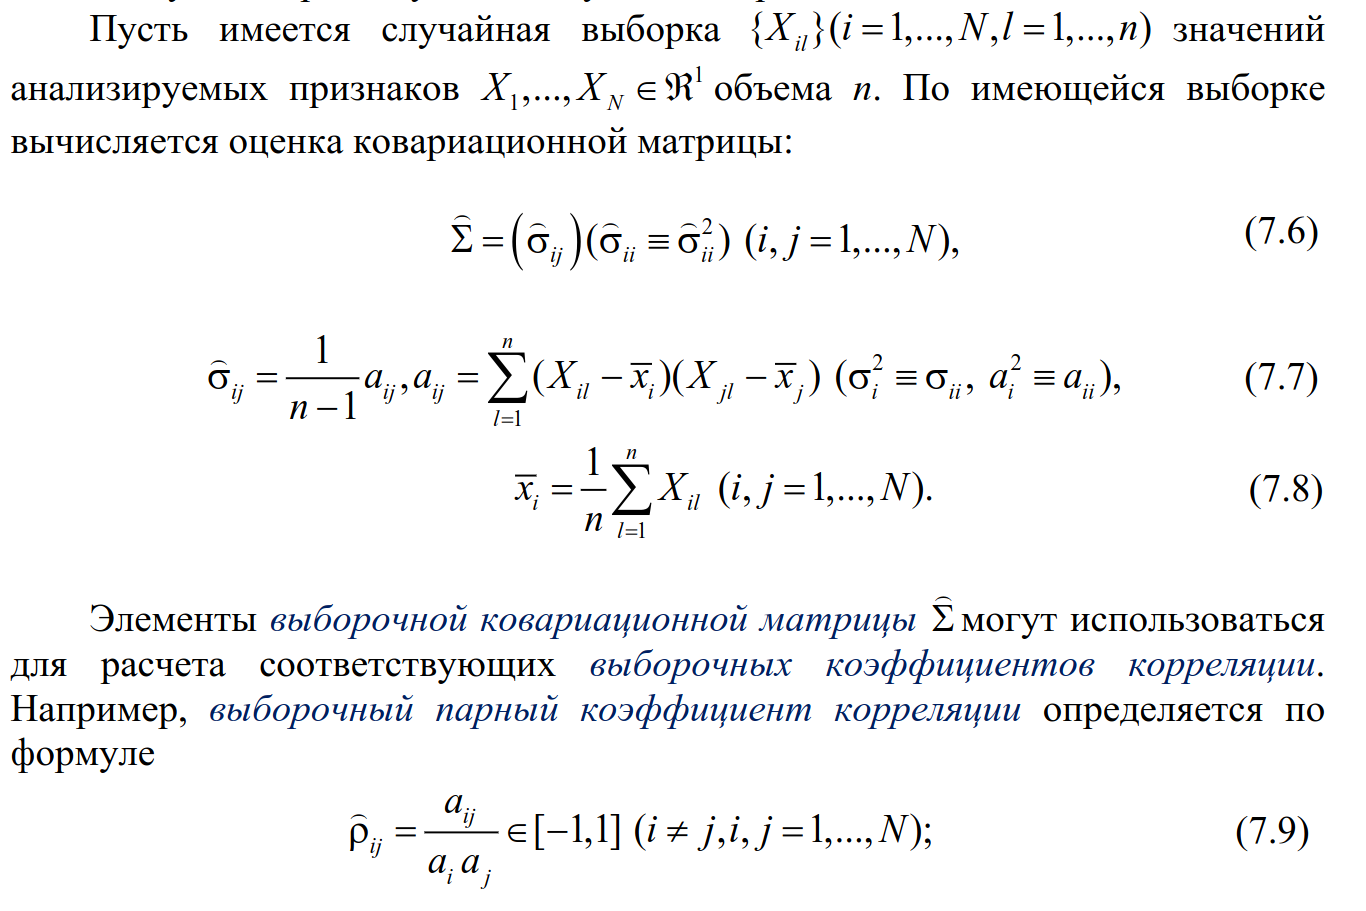

In [6]:
display(Image(filename='image1.png', width=1000))

По формуле 7.7

In [7]:
mean_val_1 = x1.mean().item()
mean_val_2 = x2.mean().item()
mean_val_3 = x3.mean().item()

mean_val_1, mean_val_2, mean_val_3

(2.974, 6.588000000000001, 2.0260000000000002)

In [8]:
a_11 = np.sum((x1 - mean_val_1)**2)
a_22 = np.sum((x2 - mean_val_2)**2)
a_33 = np.sum((x3 - mean_val_3)**2)

a_11, a_22, a_33

(np.float64(5.096199999999999),
 np.float64(19.812800000000003),
 np.float64(3.696199999999999))

In [9]:
a_1 = np.sqrt(a_11)
a_2 = np.sqrt(a_22)
a_3 = np.sqrt(a_33)

a_1, a_2, a_3

(np.float64(2.257476467208462),
 np.float64(4.4511571529210245),
 np.float64(1.9225503894566713))

In [10]:
a_12 = np.sum((x1 - mean_val_1)*(x2 - mean_val_2))
a_23 = np.sum((x2 - mean_val_2)*(x3 - mean_val_3))
a_13 = np.sum((x3 - mean_val_3)*(x1 - mean_val_1))

a_12, a_23, a_13

(np.float64(4.594399999999999),
 np.float64(2.405600000000001),
 np.float64(2.3338))

По формуле 7.9

In [11]:
r_12 = a_12 / (a_1 * a_2)
r_23 = a_23 / (a_2 * a_3)
r_13 = a_13 / (a_1 * a_3)

r_12, r_23, r_13

(np.float64(0.457227816394113),
 np.float64(0.2811077091573194),
 np.float64(0.5377280262661889))

## Определение частных коэффицентов корреляции

из Малюгин В.И._МСАДЭ_МУ

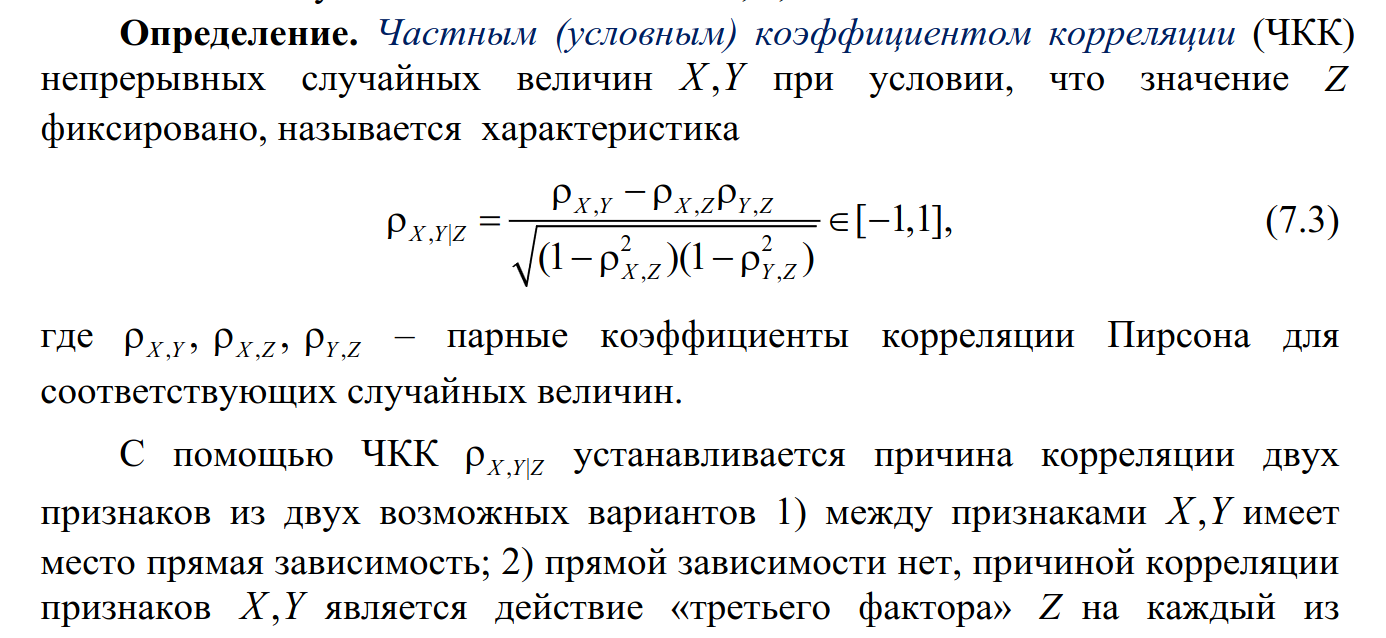

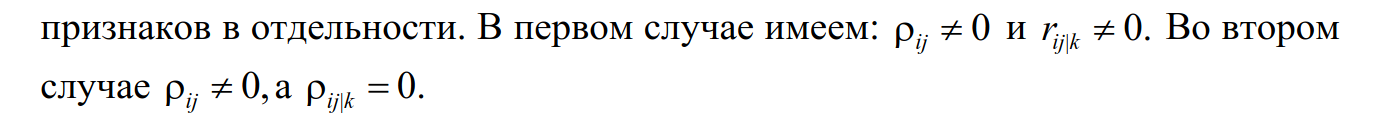

In [12]:
display(Image(filename='image2.png', width=1000))
display(Image(filename='image3.png', width=1000))

По формуле 7.3

In [13]:
r_12_3 = (r_12 - r_13 * r_23)/np.sqrt((1 - r_13**2) * (1 - r_23**2))
r_23_1 = (r_23 - r_12 * r_13)/np.sqrt((1 - r_12**2) * (1 - r_13**2))
r_13_2 = (r_13 - r_12 * r_23)/np.sqrt((1 - r_12**2) * (1 - r_23**2))

r_12_3, r_23_1, r_13_2

(np.float64(0.37827278871255676),
 np.float64(0.04700217344052275),
 np.float64(0.4794419123083884))

Разность частных и парных

In [14]:
r_12 - r_12_3, r_23 - r_23_1, r_13 - r_13_2

(np.float64(0.07895502768155621),
 np.float64(0.23410553571679665),
 np.float64(0.05828611395780048))

Разница между r_12 и r_12_3, а также r_13 и r_13_2 небольшая и значения все еще сильно отличны от нуля  
Разница между r_23 и r_23_1 велика и близка к значению r_23, а r_23_1 близка к 0, тогда можно сделать выводы

r_12_3 != 0, между 1 и 2 имеет место прямая зависимость

r_23_1 близок 0, прямой зависимости между 2 и 3 нет, причиной кореляции является действие 1 на каждый из них в отдельности

r_13_2 != 0, между 1 и 3 имеет место прямая зависимость

## Проверка статистической значимости корреляционной зависимости

Критерий значимости парного КК  

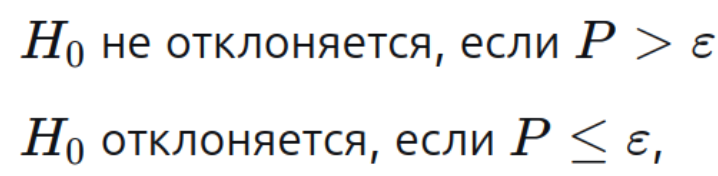

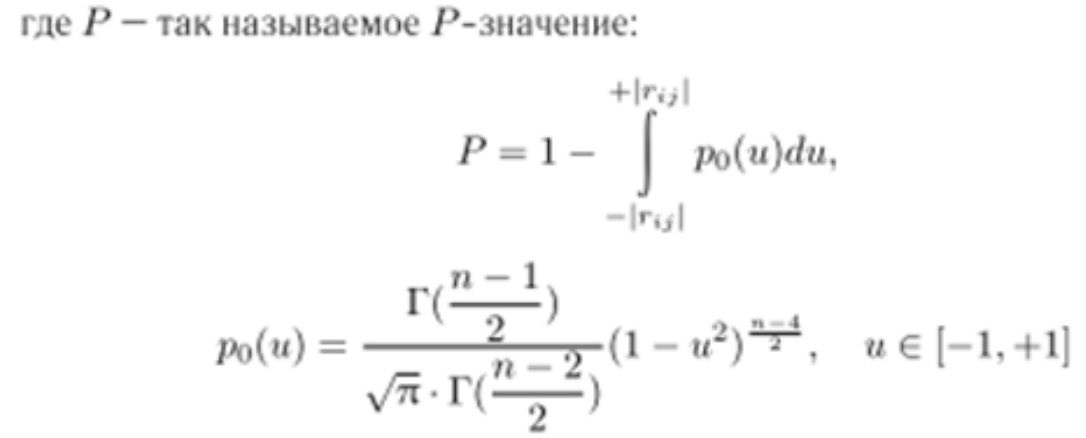

In [15]:
display(Image(filename='image4.png', width=500))
display(Image(filename='image5.png', width=800))

Практически это то же самое, что t-критерий Стьюдента с n−2 степенями свободы:

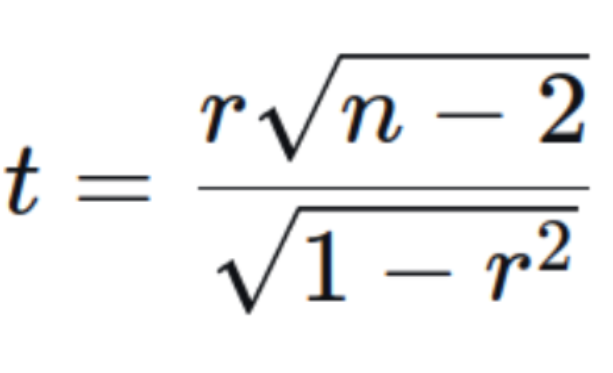

In [16]:
display(Image(filename='image6.png', width=400))

## Вычисление t-критерия для n-2

In [17]:
n = len(data[data['type'] == 3])
a = 0.05

In [18]:
t_12 = (r_12 * np.sqrt(n - 2))/(np.sqrt(1 - r_12**2))
t_23 = (r_23 * np.sqrt(n - 2))/(np.sqrt(1 - r_23**2))
t_13 = (r_13 * np.sqrt(n - 2))/(np.sqrt(1 - r_13**2))

t_12, t_23, t_13

(np.float64(3.5618919811627627),
 np.float64(2.02940459390154),
 np.float64(4.418702311848506))

Вычисление критического значения t для n-2

In [19]:
t_crit_pair = sts.t.ppf(1 - a/2, n - 2)

t_crit_pair

np.float64(2.010634757624232)

Значимость через t

In [20]:
print(f"r_12: значим: {abs(t_12) > t_crit_pair}")
print(f"r_23: значим: {abs(t_23) > t_crit_pair}")
print(f"r_13: значим: {abs(t_13) > t_crit_pair}")

r_12: значим: True
r_23: значим: True
r_13: значим: True


Все три парных коэффициента корреляции статистически значимы, но 23 находится на грани(тк значение очень близко к t-критическому)

## Вычисление p-значение

In [21]:
p_12 = 2 * (1 - sts.t.cdf(abs(t_12), n - 2))
p_23 = 2 * (1 - sts.t.cdf(abs(t_23), n - 2))
p_13 = 2 * (1 - sts.t.cdf(abs(t_13), n - 2))

p_12, p_23, p_13

(np.float64(0.0008434624723707707),
 np.float64(0.047981493369188444),
 np.float64(5.647610402292891e-05))

Значимость через p

In [22]:
print(f"r_12: значим: {p_12 < a}")
print(f"r_23: значим: {p_23 < a}")
print(f"r_13: значим: {p_13 < a}")

r_12: значим: True
r_23: значим: True
r_13: значим: True


Все три парных коэффициента корреляции статистически значимы, но 23 находится на грани(тк значение очень близко к a)

Критерий значимости частного КК  

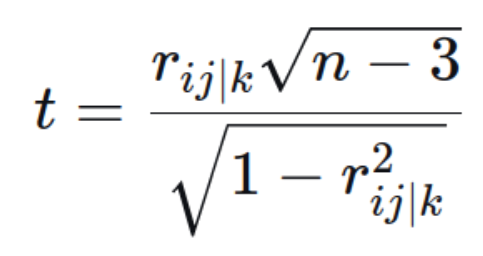

In [23]:
display(Image(filename='image7.png', width=500))

## Вычисление t-критерия для n-3

In [24]:
t_12_3 = (r_12_3 * np.sqrt(n - 3))/(np.sqrt(1 - r_12_3**2))
t_23_1 = (r_23_1 * np.sqrt(n - 3))/(np.sqrt(1 - r_23_1**2))
t_13_2 = (r_13_2 * np.sqrt(n - 3))/(np.sqrt(1 - r_13_2**2))

t_12_3, t_23_1, t_13_2

(np.float64(2.8014733880303386),
 np.float64(0.32258719410526293),
 np.float64(3.745427265822388))

Вычисление критического значения t для n-3

In [25]:
t_crit_part = sts.t.ppf(1 - a/2, n - 3)

t_crit_part

np.float64(2.0117405137297655)

Значимость через t

In [26]:
print(f"r_12_3: значим: {abs(t_12_3) > t_crit_part}")
print(f"r_23_1: значим: {abs(t_23_1) > t_crit_part}")
print(f"r_13_2: значим: {abs(t_13_2) > t_crit_part}")

r_12_3: значим: True
r_23_1: значим: False
r_13_2: значим: True


Коэффиценты корреляции 12 и 13 значимы, а 23 нет, тк не t не превосходит t критическое

## Вычисление p-значение

In [27]:
p_12_3 = 2 * (1 - sts.t.cdf(abs(t_12_3), n - 3))
p_23_1 = 2 * (1 - sts.t.cdf(abs(t_23_1), n - 3))
p_13_2 = 2 * (1 - sts.t.cdf(abs(t_13_2), n - 3))

p_12_3, p_23_1, p_13_2

(np.float64(0.007363589661746328),
 np.float64(0.7484385758269321),
 np.float64(0.0004911883641607329))

Значимость через p

In [28]:
print(f"r_12_3: значим: {p_12_3 < a}")
print(f"r_23_1: значим: {p_23_1 < a}")
print(f"r_13_2: значим: {p_13_2 < a}")

r_12_3: значим: True
r_23_1: значим: False
r_13_2: значим: True


Коэффиценты корреляции 12 и 13 значимы, а 23 нет, тк p превосходит а

## Множественный коэффицент корреляции

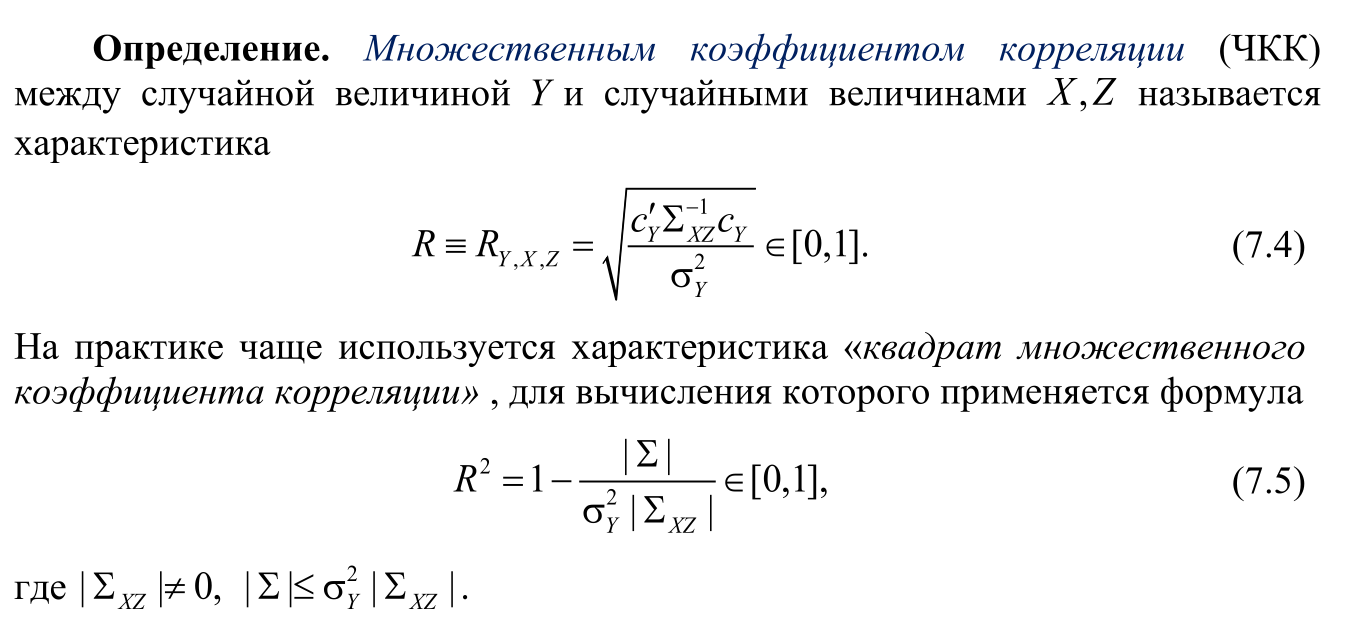

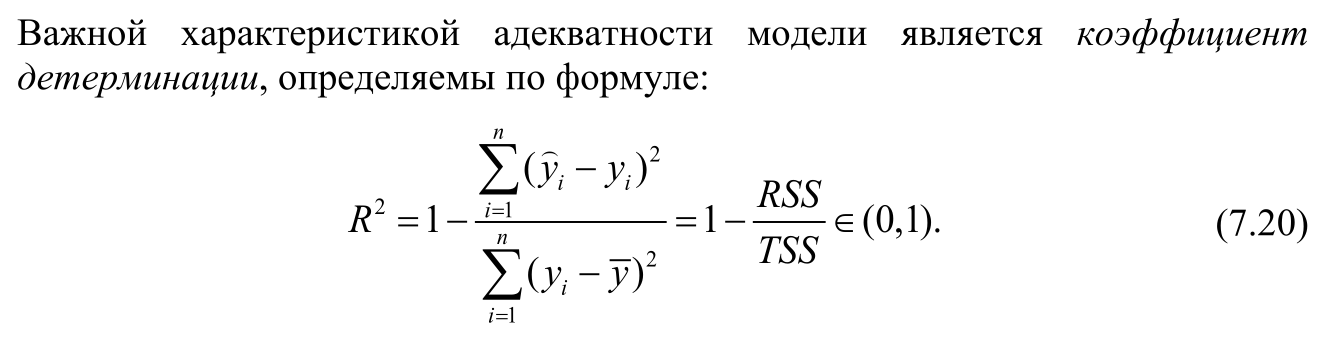

In [29]:
display(Image(filename='image8.png', width=1000))
display(Image(filename='image9.png', width=1000))

In [30]:
R_1_23 = np.sqrt((r_12**2 + r_13**2 - 2 * r_12 * r_13 * r_23)/(1 - r_23**2))

R_1_23

np.float64(0.6251935438247318)

Вычисление R2 модели МЛР x1 на (x2, x3) для сравнения с ВМКК

In [31]:
X_reg = np.column_stack([np.ones_like(x2), x2, x3])
y_reg = x1
beta, *_ = np.linalg.lstsq(X_reg, y_reg, rcond=None)
y_hat = X_reg @ beta
RSS = np.sum((y_reg - y_hat)**2)
TSS = np.sum((y_reg - y_reg.mean())**2)
R2 = 1 - RSS/TSS
R = np.sqrt(R2)

R_1_23, R2, R

(np.float64(0.6251935438247318),
 np.float64(0.39086696724012737),
 np.float64(0.6251935438247322))

Значение ВМКК R_1_23 = 0.625... почти в точности совпадает с корнем из коэффициента детерминациии x1 на (x2, x3): sqrt(R2) = 0.625...

## F-статистика для проверки значимости ВМКК

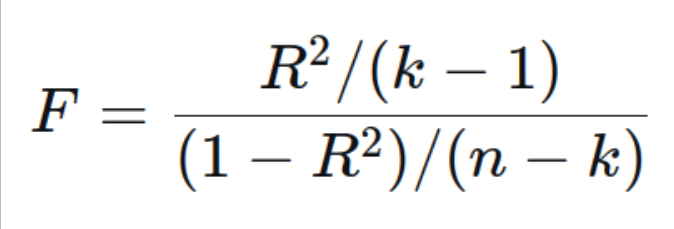

In [32]:
display(Image(filename='image10.png', width=600))

In [33]:
k = 3

In [34]:
F_1_23 = (R_1_23**2/(k-1))/((1 - R_1_23**2)/(n - k))

F_1_23

np.float64(15.079421466482763)

In [35]:
F_crit = sts.f.ppf(1-a, k-1, n-k)

F_crit

np.float64(3.1950562807372145)

In [36]:
print(f"F_1_23: значим: {F_1_23 > F_crit}")

F_1_23: значим: True


In [37]:
p_F = 1 - sts.f.cdf(F_1_23, k-1, n-k)

p_F

np.float64(8.72439984900275e-06)

F_1_23 превышает критическое значение F, p_F < 0.001. Следовательно, на уровне a = 0.05 гипотеза H0: R_1_23 = 0 отвергается — множественный коэффициент корреляции статистически значим, между x1 и набором (x2, x3) существует значимая линейная зависимость.

## Вывод
Все три парных КК значимы (a = 0.05). После исключения влияния третьего фактора r_12_3 и r_13_2 остались значимыми — между X1-X2 и X1-X3 имеет место непосредственная связь. Частный r_23_1 незначим, значит корреляция X2-X3 обусловлена влиянием X1.

ВМКК R_1_23, R2, F (p < 0.001) - значим. Совпадает с sqrt(R2) модели МЛР x1 ~ x2 + x3. Связь x1 с набором (x2, x3) статистически значимая.